# 04 Scalability Analysis

Implements the documented 12-criterion decision model under three weight sets.
Scores are evidence-backed ordinal judgments and are not a safety or autonomy leaderboard.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd()
assert (ROOT / "data").exists(), "Execute with project root as the working directory."
pd.set_option("display.max_colwidth", 120)


In [2]:
scores=pd.read_csv(ROOT/"data/reporting/scalability_weighted_scores.csv")
scores.sort_values(["weighting_scheme","rank_within_scheme"])

,company_id,company_name,weighted_sum,weight_sum,weighted_score_1_5,weighting_scheme,rank_within_scheme
3,4,Mobileye,452,100,4.52,Baseline,1
2,3,NVIDIA,421,100,4.21,Baseline,2
0,1,Tesla,377,100,3.77,Baseline,3
1,2,Waymo,351,100,3.51,Baseline,4
7,4,Mobileye,451,100,4.51,L4 operator lens,1
6,3,NVIDIA,435,100,4.35,L4 operator lens,2
5,2,Waymo,365,100,3.65,L4 operator lens,3
4,1,Tesla,361,100,3.61,L4 operator lens,4
11,4,Mobileye,450,100,4.50,Platform supplier lens,1
10,3,NVIDIA,438,100,4.38,Platform supplier lens,2


In [3]:
detail=pd.read_csv(ROOT/"data/reporting/scalability_score_detail.csv")
profile=detail.pivot(index="criterion_name",columns="company_name",values="score_1_5")
profile

company_name,Mobileye,NVIDIA,Tesla,Waymo
criterion_name,,,,
Commercial flexibility,5,5,2,3
Cost scalability,5,4,5,2
Data scale,5,3,5,4
Deployment maturity,5,4,4,5
Geographic scalability,5,5,5,2
Hardware dependence,4,2,4,3
In-vehicle compute,4,5,4,4
OEM or fleet integration,5,5,2,3
Regulatory exposure,4,4,2,3


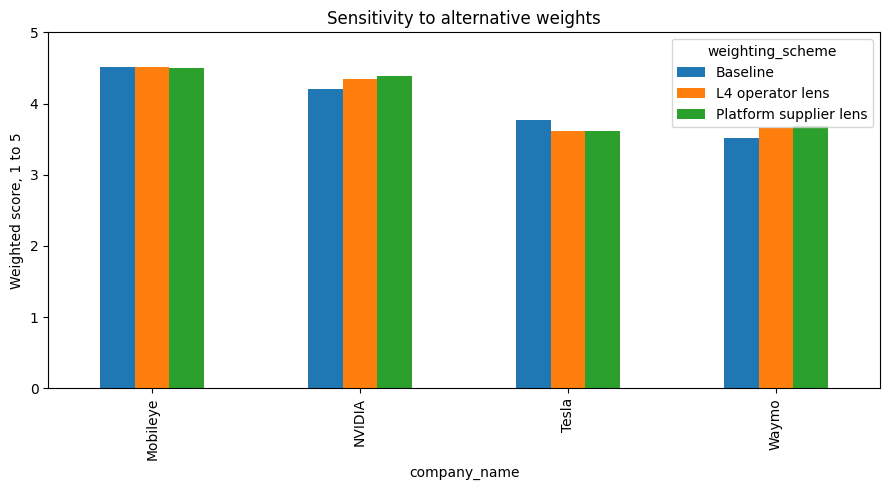

In [4]:
ax=scores.pivot(index="company_name",columns="weighting_scheme",values="weighted_score_1_5").plot(kind="bar",figsize=(9,5))
ax.set_ylim(0,5)
ax.set_ylabel("Weighted score, 1 to 5")
ax.set_title("Sensitivity to alternative weights")
plt.tight_layout()
plt.show()

**Interpretation:** The model is most useful for diagnosing architecture and commercialization tradeoffs. A single rank should not be presented as proof that one company is safer, more autonomous, or universally superior.